### Import Libraries : Exhaustive list, not all being used

In [6]:
from PIL import Image

import os
dir_path = 'C:/Admin/CQF Course/Python Labs/Self HJM Model'

In [2]:
# data manipuation
import pandas as pd
import numpy as np

# panda technical analysis 
import pandas_ta as ta

# data visualization
import matplotlib as mpl

import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = (10,6)
plt.style.use ='seaborn'
plt.rcParams['font.size'] = 8

#-------------------------------------------------------------------------------------------------------------
# statistical visual representation
import seaborn as sns

import cufflinks as cf                                                        # new package - cufflinks
cf.set_config_file(offline=True, theme='pearl',dimensions=((1000,600)))       # cf.set_config() -- (w,h)

import plotly.express as px
px.defaults.width, px.defaults.height = 1000,600

#-------------------------------------------------------------------------------------------------------------
# Self organizing maps(SOM)
from minisom import MiniSom

#-------------------------------------------------------------------------------------------------------------
# K-means clustering(KMC)
from sklearn.cluster import KMeans

# scikit learn(sklearn) package is used primarily for machine learning
# always remember to perform pre-processing and model selcetion before using model implementation
import sklearn
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.model_selection import train_test_split,TimeSeriesSplit,cross_val_score,GridSearchCV,RandomizedSearchCV

from sklearn.pipeline import Pipeline

# sklearn evaluation metrics
from sklearn.metrics import precision_recall_curve, roc_curve,RocCurveDisplay,ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, f1_score, recall_score,precision_score,roc_auc_score,auc
from sklearn.metrics import classification_report, confusion_matrix

# Regression
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet

# K-means clustering(KMC)
from sklearn.cluster import KMeans

# Support Vector Machine(SVM)
from sklearn.svm import SVC

# DTEM(Decision Trees and Ensemble Models) - Bagging - Random Forest
from sklearn.ensemble import RandomForestClassifier

# K nearest neighbours(KNN)
from sklearn.neighbors import KNeighborsClassifier

# Principal Component Analysis(PCA)
from sklearn.decomposition import PCA

#-------------------------------------------------------------------------------------------------------------
# DTEM(Decision Trees and Ensemble Models) - Boosting - Gradient Boosting(Extreme Gradient Boosting)
from xgboost import XGBClassifier,plot_importance,to_graphviz

#-------------------------------------------------------------------------------------------------------------
# statistical analysis & optimization
import scipy.stats as scs
import scipy.optimize as sco
from scipy.interpolate import interp1d
from scipy.integrate import simpson
from scipy.interpolate import CubicSpline

# statsmodels is a Python package that provides a complement to scipy for statistical computations
# mainly for timeseries analysis
import statsmodels.api as sm
from statsmodels.tsa.api import VAR
from statsmodels.tsa.statespace.varmax import VARMAX
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, coint, grangercausalitytests
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

#-------------------------------------------------------------------------------------------------------------
# Nelson Siegel Svensson Model
from nelson_siegel_svensson import NelsonSiegelCurve, NelsonSiegelSvenssonCurve
from nelson_siegel_svensson.calibrate import calibrate_ns_ols, calibrate_nss_ols

#-------------------------------------------------------------------------------------------------------------
# SABR(Stochastic Alpha, Beta, Rho)
from pysabr import Hagan2002LognormalSABR
from pysabr import Hagan2002NormalSABR
from pysabr.helpers import year_frac_from_maturity_label

#-------------------------------------------------------------------------------------------------------------
# Shapley values, used in DTEM
import shap

#-------------------------------------------------------------------------------------------------------------
# Quantlib package
from QuantLib import *

#-------------------------------------------------------------------------------------------------------------
# Pyfolio package used for strategy backtesting
import pyfolio as pf

# to reload another python script 
from importlib import reload

# Ignore warnings - optional
import warnings
warnings.filterwarnings('ignore')

# data retrival
import yfinance as yf
 
# float display
pd.options.display.float_format = '{:0.4f}'.format

# operating system
import os

# Image package
from PIL import Image

# table formation
from tabulate import tabulate

# datetime handling
from datetime import datetime

import itertools

# ARCH Toolbox
from arch import arch_model

Module "zipline.assets" not found; mutltipliers will not be applied to position notionals.


### Heath Jarrow Morton (HJM) Model introduction

- HJM framework specifies forward rate dynamics directly.
- Initial Forward curve exogenous
- Forward rate drift is fully determined by forward rate volatility
- HJM framework contains all interest rate models driven by browian motion

### HJM Model Formula

Instantanous forward rate with maturity  $\tau$ is assumed to satisfy stochastic differential equation

$ df(t,\tau) = m(t,\tau) dt + \sigma(t,\tau) dX(t)$

where $f(0,\tau)$ = exogenous initial forward curve

dX = browian motion under risk-neutral measure

$\sigma(t,\tau)$ = volatility process

$m(t,\tau)$ = drift process(fully determined by $\sigma(t,\tau)$)

In [11]:
os.path.join(dir_path,"pic_1.png")

'C:/Admin/CQF Course/Python Labs/Self HJM Model\\pic_1.png'

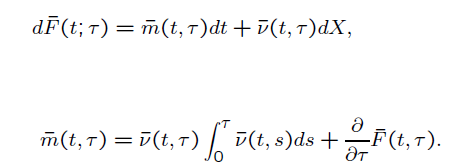

In [14]:
Image.open(os.path.join(dir_path,'pic_1.png'))

### Assumptions of HJM Model & Usage

- The model assumes that forward rate is driven by volatility because the volatility in the market for future contrcats can be predicted

- Another assumption presented by the model is that price of each security is observable

- The model doesnt explain all the complexities that come from changing term structure

usage of HJM model is to determine prices of securities which are impacted by interest rate fluctuations, especially IR derivatives.


### HJM Model Pricing and Calibration

- Calibrate HJM Model with historical daily yield curve data ove the last 5 years.The yield curve structure contains 51 tenors ranging from 1M to 25Y.

- The Pricipal Componant Analysis is then used to identify common factors which are driving movements in these rates.

- Once the volatility factors are identified, cubic spline interpolation is used to fir these factors.These interpolators are then used to generate discrete mesh of tenors for the purpose of monte carlo simulations.

- Risk Neutral drift function is caluclated using numerical integration over fitted volatility functions.

In [3]:
df = pd.read_csv("C:/Admin/CQF Course/Python Labs/Self HJM Model/hjm_data.csv").set_index('time')

### Evolution of Forward Rate

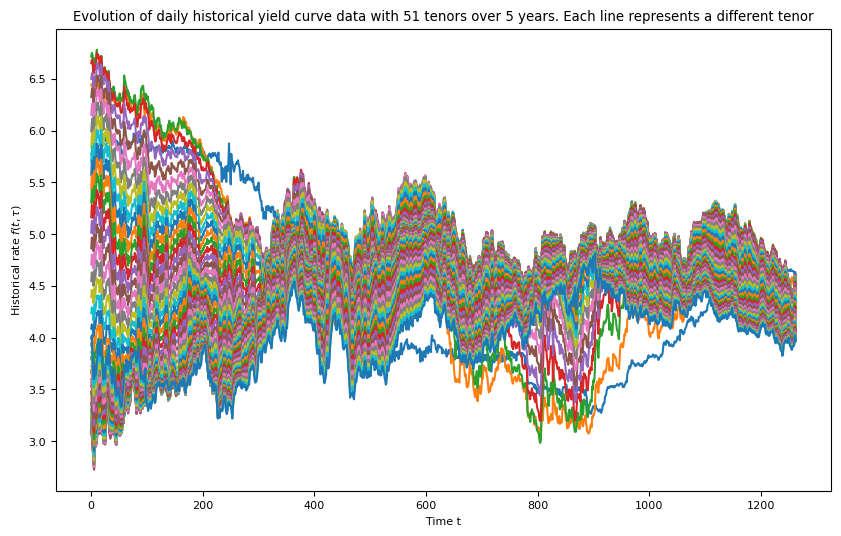

In [4]:
hist_timelines = list(df.index)
tenors = [eval(x) for x in df.columns]

hist_rates = np.array(df)
plt.plot(hist_rates)
plt.xlabel('Time t')                                                  
plt.ylabel(r'Historical rate $f(t,\tau)$')   
plt.title(r'Evolution of daily historical yield curve data with 51 tenors over 5 years. Each line represents a different tenor')
plt.show()

### Yield Curve/ Term Structure of IR

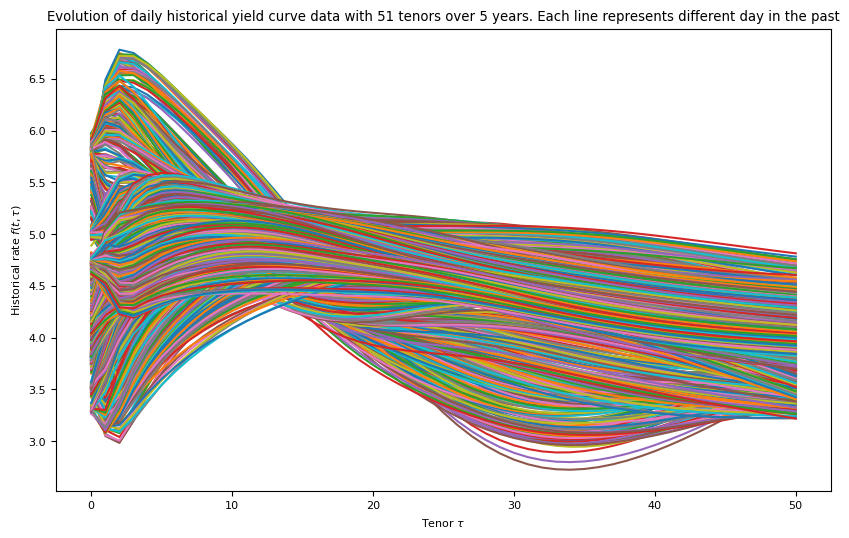

In [5]:
plt.plot(hist_rates.transpose())
plt.xlabel(r'Tenor $\tau$')                                                  
plt.ylabel(r'Historical rate $f(t,\tau)$')   
plt.title(r'Evolution of daily historical yield curve data with 51 tenors over 5 years. Each line represents different day in the past')
plt.show()

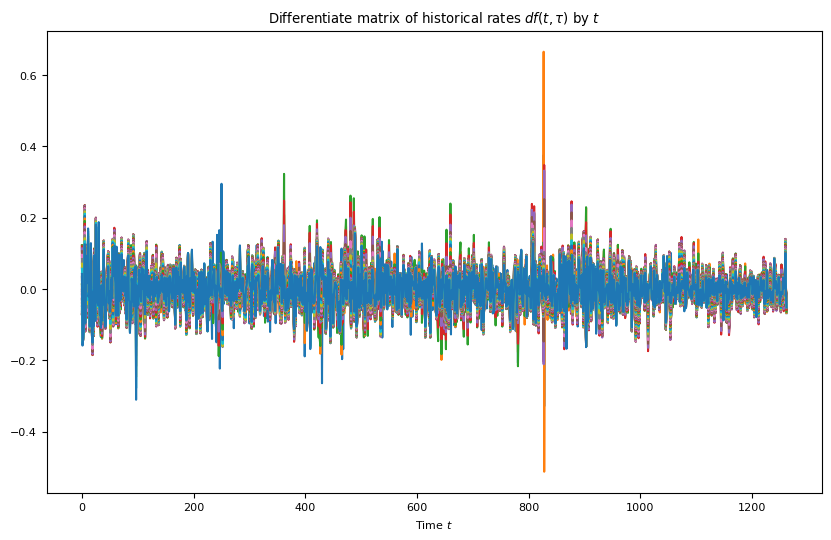

In [6]:
diff_rates = np.diff(hist_rates, n= 1, axis = 0)
hist_rates.shape[1]==diff_rates.shape[1]
plt.plot(diff_rates), 
plt.xlabel(r'Time $t$')
plt.title(r'Differentiate matrix of historical rates $df(t,\tau)$ by $t$')
plt.show()

### Calculate covariance matrix, Eigenvalues and Eigenvectors

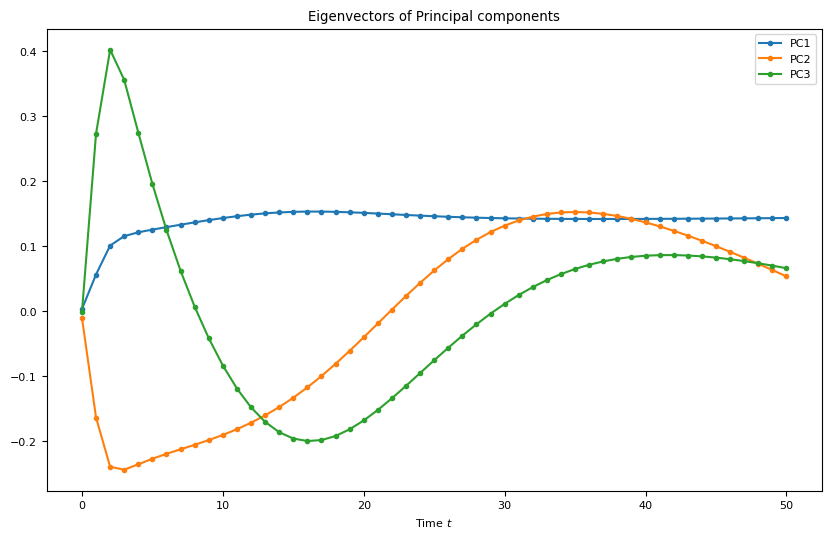

In [7]:
cov_matrix = np.cov(diff_rates,rowvar= False)*252

eigenvalues, eigenvectors= np.linalg.eig(cov_matrix)
idx = np.argsort(eigenvalues)[::-1]
eigenvectors = eigenvectors[:,idx]
eigenvalues[::-1].sort()

df_eigenvec = pd.DataFrame(eigenvectors[:,:3], columns =['PC1','PC2','PC3'])

princ_comp = eigenvectors[:,:3]
princ_eigval = eigenvalues[:3]

plt.plot(df_eigenvec,marker='.')
plt.xlabel(r'Time $t$')
plt.title('Eigenvectors of Principal components')
plt.legend(['PC1','PC2','PC3'])
plt.show()

### Discretized Volatility 

#### SQRT(Eigenvalue)* Eigenvector formual has been used to rescale volatility

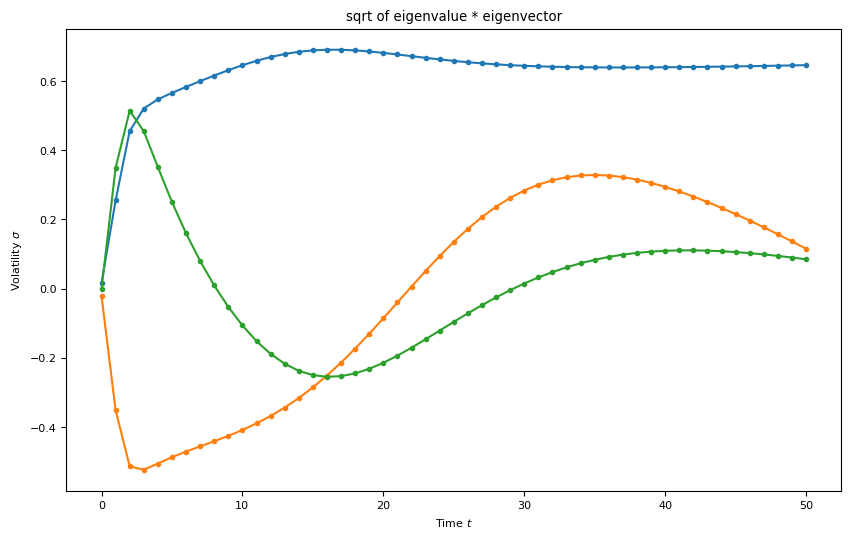

In [8]:
sqrt_eigval = princ_eigval ** .5
tmp_m = np.vstack([sqrt_eigval for i in range(princ_comp.shape[0])])
vols = sqrt_eigval*princ_comp

plt.plot(vols,marker='.')
plt.xlabel(r'Time $t$')
plt.ylabel(r'Volatility $\sigma$')
plt.title('sqrt of eigenvalue * eigenvector')
plt.show()

### Fitted Volatiity

In [9]:
def get_matrix_column(mat,i):
    return np.array(mat[:,i].flatten())

class PolinomialInterpolator:
    def __init__(self,params):
        self.params = params
        assert type(params) == np.ndarray
        
    def calc(self,x):
        p_coef = self.params
        value = np.polyval(p_coef,x)
        
        return value
    
fitted_vols = []   

def fit_volatility(i,degree,title):
    vol = get_matrix_column(vols,i)
    fitted_vol = PolinomialInterpolator(np.polyfit(tenors,vol,deg =degree))
    plt.plot(tenors,vol,marker='.',label='Discretized volatility')
    plt.plot(tenors, [fitted_vol.calc(x) for x in tenors], label='Fitted volatility')
    plt.title(title)
    plt.xlabel(r'Time $t$')
    plt.legend();
    fitted_vols.append(fitted_vol)

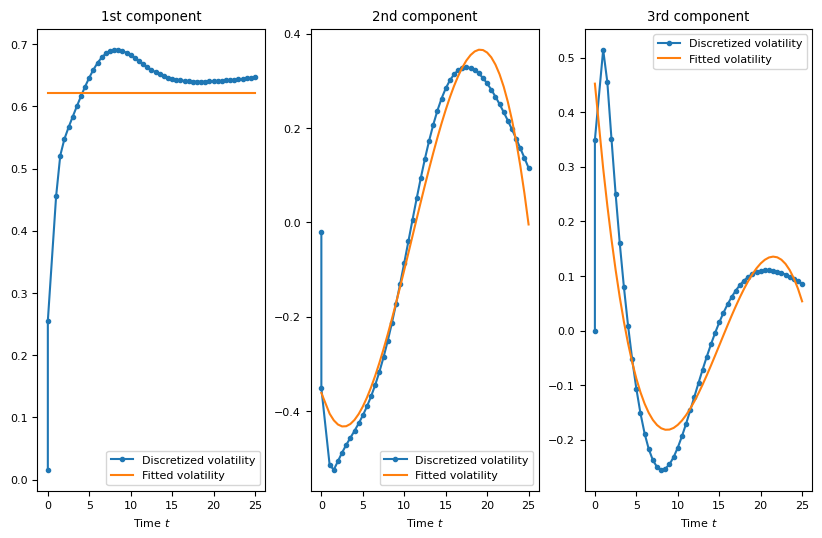

In [10]:
plt.subplot(1, 3, 1), fit_volatility(0, 0, '1st component');
plt.subplot(1, 3, 2), fit_volatility(1, 3, '2nd component');
plt.subplot(1, 3, 3), fit_volatility(2, 3, '3rd component');
plt.show()

### Risk Neutral Drift

In [11]:
mc_tenors = np.linspace(0,25,51)
mc_vols = np.array([[fitted_vol.calc(x) for x in tenors] for fitted_vol in fitted_vols])

def integrate(f,x0,x1,dx):
    n = (x1-x0)/dx + 1
    out = 0
    for i,x in enumerate(np.linspace(x0, x1, int(n))):
        if i==0 or i ==n-1:
            out = out + 0.5*f(x)  # not adjusted by *0.5 because of repeating terms x1...xn-1 - see trapezoidal rule
        else:
            out = out + f(x)
            
    out = out*dx
    return out  

In [12]:
# This funciton carries out integration for all principal factors. 
# It uses the fact that volatility is function of time in HJM model

def integrate_all(tau, fitted_vols):
    out = 0
    for fitted_vol in fitted_vols:
        assert isinstance(fitted_vol,PolinomialInterpolator)
        out = out + integrate(fitted_vol.calc,0,tau,0.01) *fitted_vol.calc(tau)
    
    return out
    

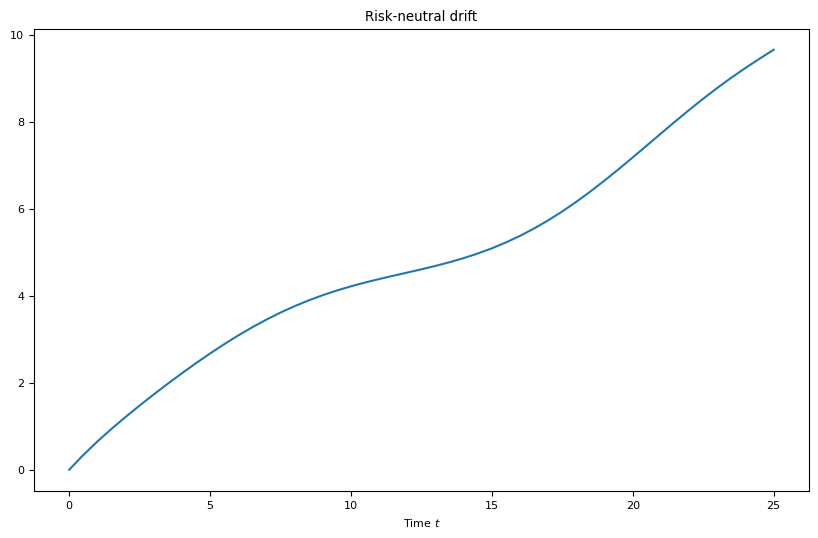

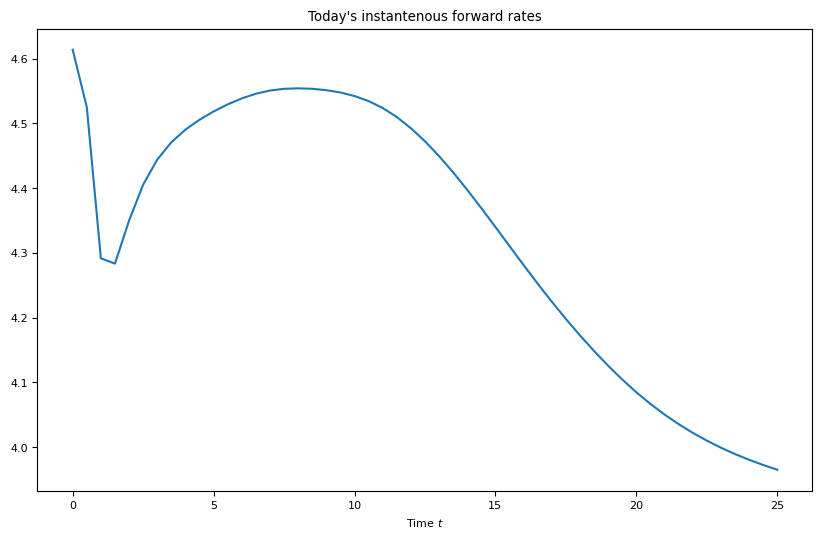

In [13]:
mc_drift = np.array([integrate_all(tau, fitted_vols) for tau in mc_tenors])
plt.plot(mc_tenors,mc_drift)
plt.title('Risk-neutral drift')
plt.xlabel(r'Time $t$')
plt.show()

# this is the last row from hjm_data - means current date t = 0
curve_spot = hist_rates[-1,:]
plt.plot(mc_tenors,curve_spot)
plt.title('Today\'s instantenous forward rates')
plt.xlabel(r'Time $t$')
plt.show()

### Simulation of Forward rate across time- current date t = 0 to future dates

In [14]:
proj_rates = []
proj_timeline = np.linspace(0,5,500)

def simulations(curve_spot,tenors, drift, vols, timeline):
    vols = vols.transpose()
    len_tenors = len(tenors)
    len_vols = len(vols)
    
    f = np.zeros((len(proj_timeline),len(mc_tenors)))
    f[0] = curve_spot
    
    for t in range(1,len(timeline)):
        dt = timeline[t]-timeline[t-1]
        sqrt_dt = np.sqrt(dt)

        for tenor in range(1,len(tenors)): 
            value = f[t-1, tenor] + dt*drift[tenor]
            randNum_times_vol = vol[tenor]*np.random.normal(size = (vols.shape[1]))
            sum_vol= np.sum(randNum_times_vol, axis=1)
            vol_times_sqrtTime = sum_vol*sqrt_dt
            value += vol_times_sqrtTime


            term_1 = drift*dt

            df = term_1 + term_2_3
            f[t] = f[t-1] + df
        
    return f

IndentationError: expected an indented block after 'for' statement on line 16 (2546744332.py, line 17)

In [30]:
vols[tenor]*np.random.normal(size = vols.shape[1])

IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

In [37]:
vols = mc_vols.T
tenor = 1
randNum_times_vol = vols[tenor]*np.random.normal(size = vols.shape[1])

In [ ]:
forward_curve = simulations(curve_spot,mc_tenors, mc_drift, mc_vols, proj_timeline)

In [ ]:
forward_curve[-1]